# Graphiques

Chaque graphique est produit par une fonction de `src/visualisation.py` et enregistré dans `figures/`.

In [1]:
import os
import sys

import geopandas as gpd
import pandas as pd
import yaml

# on se place à la racine du projet
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

from src.variables import build_parts_croissance
from src.visualisation import map_gares

communes = gpd.read_parquet("data/clean/base_finale/base_finale_communes_variables.parquet")
gares = gpd.read_parquet("data/clean/base_finale/base_finale_gares.parquet")
gares_annees = pd.read_parquet("data/clean/base_finale/base_finale_gares_annees.parquet")
os.makedirs("figures", exist_ok=True)

## Carte 7 : les gares et la croissance de la population

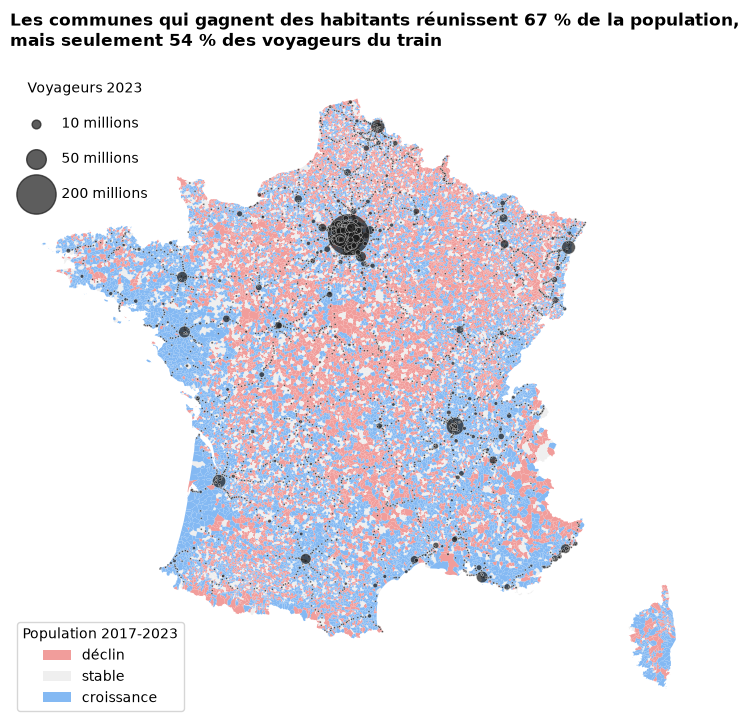

In [2]:
part_pop, part_voy = build_parts_croissance(communes, gares_annees, config["annee_fin"])
titre = (f"Les communes qui gagnent des habitants réunissent {part_pop:.0f} % de la population,\n"
         f"mais seulement {part_voy:.0f} % des voyageurs du train")
map_gares(communes, gares, gares_annees, config["annee_fin"], titre, "figures/07_carte_gares.png");

La taille des bulles est proportionnelle au nombre de voyageurs de la gare en 2023. On observe que les grandes gares se concentrent dans les métropoles, dont Paris, qui perd des habitants. La croissance démographique se fait surtout sur la façade atlantique, autour de Toulouse, de Lyon et dans les Alpes. 